<a href="https://colab.research.google.com/github/xegor4ikx/labs2/blob/main/%D0%9A%D0%BE%D0%BF%D1%96%D1%8F_%D0%B7%D0%B0%D0%BF%D0%B8%D1%81%D0%BD%D0%B8%D0%BA%D0%B0_%22%D0%9B%D0%A0_10_%D0%9C%D0%9D_%D0%9A%D0%B5%D1%80%D0%B0%D1%81_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Силін Єгор  
**Група:** ФІТ 3-9
**Дата:** 24.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготовка робочого середовища: імпорти
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, log_loss

# Фіксуємо зерно генераторів випадкових чисел (Python, NumPy, TensorFlow) для відтворюваності
SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()  # детерміновані операції TensorFlow

print('TensorFlow:', tf.__version__)
print('Keras:', keras.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'не виявлено (навчання на CPU)')

TensorFlow: 2.21.0
Keras: 3.13.2
GPU: не виявлено (навчання на CPU)


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантаження Fashion MNIST (60 000 навчальних і 10 000 тестових зображень 28×28)
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print('x_train:', x_train.shape, x_train.dtype)
print('y_train:', y_train.shape, y_train.dtype)
print('x_test: ', x_test.shape, x_test.dtype)
print('y_test: ', y_test.shape, y_test.dtype)
print('Кількість класів:', len(class_names))
print('Розподіл класів у навчальній вибірці:', np.bincount(y_train))

x_train: (60000, 28, 28) uint8
y_train: (60000,) uint8
x_test:  (10000, 28, 28) uint8
y_test:  (10000,) uint8
Кількість класів: 10
Розподіл класів у навчальній вибірці: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

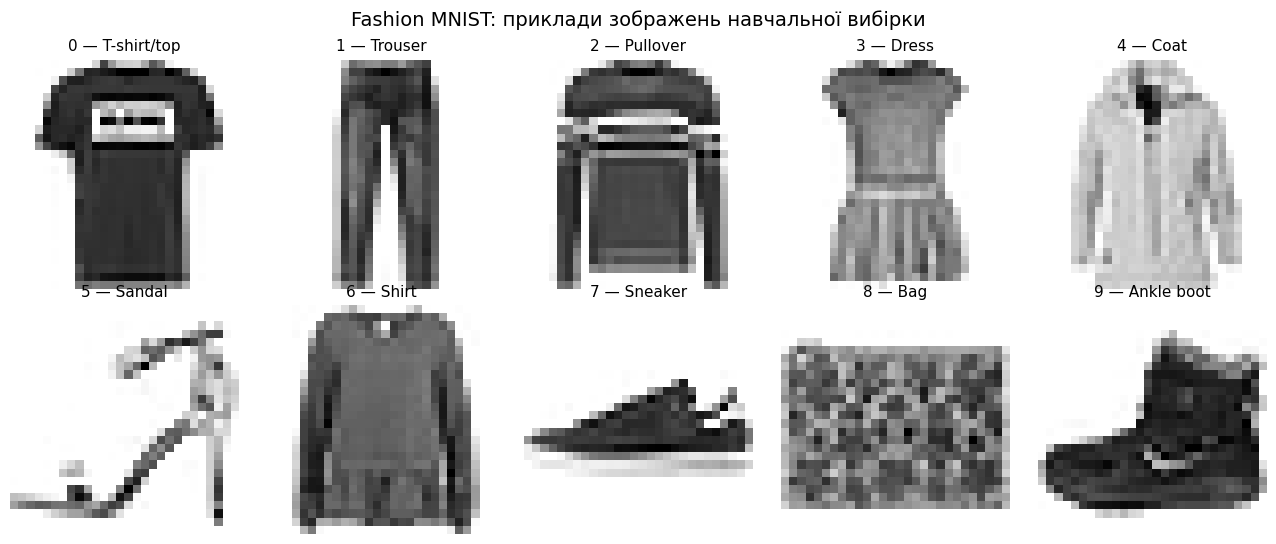

In [3]:
# По одному (першому) зображенню кожного з 10 класів навчальної вибірки
first_idx = [int(np.where(y_train == c)[0][0]) for c in range(10)]

plt.figure(figsize=(13, 5.5))
for k, i in enumerate(first_idx):
    plt.subplot(2, 5, k + 1)
    plt.imshow(x_train[i], cmap='binary')
    plt.title(f'{y_train[i]} — {class_names[y_train[i]]}', fontsize=11)
    plt.axis('off')
plt.suptitle('Fashion MNIST: приклади зображень навчальної вибірки', fontsize=14)
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Переводимо пікселі з uint8 [0; 255] у float32 [0; 1].
# Перевірка dtype захищає від повторного ділення на 255 при перезапуску комірки.
if x_train.dtype != np.float32:
    x_train = x_train.astype('float32') / 255.0
    x_test = x_test.astype('float32') / 255.0

print('Тип даних:', x_train.dtype, x_test.dtype)
print(f'x_train: min = {x_train.min():.1f}, max = {x_train.max():.1f}, середнє = {x_train.mean():.3f}')
print(f'x_test:  min = {x_test.min():.1f}, max = {x_test.max():.1f}, середнє = {x_test.mean():.3f}')

Тип даних: float32 float32
x_train: min = 0.0, max = 1.0, середнє = 0.286
x_test:  min = 0.0, max = 1.0, середнє = 0.287


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

**Пояснення вибору гіперпараметрів:**

- **Архітектура 784 → 256 → 128 → 10.** Шар Flatten перетворює зображення 28×28 у вектор із 784 ознак. Два приховані шари зі спадною кількістю нейронів (256 і 128) поступово стискають представлення до 10 класів. Такої місткості (≈235 тис. параметрів) достатньо, щоб повнозв’язна мережа на Fashion MNIST перевищила поріг 0,87. Модель при цьому навчається швидко і не так схильна до перенавчання, як шари на 512–1024 нейрони. Значно менші шари (32–64) дають помітно нижчу точність.
- **Dropout = 0,3.** Під час навчання випадково вимикається 30 % нейронів кожного прихованого шару. Це зменшує взаємну підлаштованість нейронів і перенавчання. Значення 0,2–0,5 вважаються типовими; 0,3 — компроміс між регуляризацією та швидкістю збіжності.
- **Швидкість навчання Adam = 0,001.** Це стандартне значення для Adam: збіжність стабільна й досить швидка. Зі значенням 0,01 навчання часто «стрибає», а з 0,0001 стає надто повільним. Додатково ReduceLROnPlateau зменшує швидкість удвічі, якщо val_loss перестає спадати, що допомагає точніше налаштувати ваги наприкінці навчання.
- **Функція втрат** — sparse_categorical_crossentropy, бо мітки задано цілими числами 0–9 (без one-hot кодування); **метрика** — accuracy.

In [5]:
# Базова модель: Flatten -> Dense(256, ReLU) -> Dropout -> Dense(128, ReLU) -> Dropout -> Dense(10, softmax)
HIDDEN_UNITS = [256, 128]   # нейрони у прихованих шарах
DROPOUT_RATE = 0.3          # частка нейронів, що вимикаються під час навчання
LEARNING_RATE = 1e-3        # початкова швидкість навчання Adam

keras.utils.set_random_seed(SEED)
model = keras.Sequential(name='baseline_mlp')
model.add(keras.Input(shape=(28, 28)))
model.add(layers.Flatten(name='flatten'))
for i, units in enumerate(HIDDEN_UNITS):
    model.add(layers.Dense(units, activation='relu', name=f'dense_{i + 1}'))
    model.add(layers.Dropout(DROPOUT_RATE, name=f'dropout_{i + 1}'))
model.add(layers.Dense(10, activation='softmax', name='output'))

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='sparse_categorical_crossentropy',  # мітки — цілі числа 0..9
    metrics=['accuracy'],
)
print('Модель створено та скомпільовано.')

Модель створено та скомпільовано.


### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# 10 % навчальної вибірки відокремлюємо для валідації (стратифіковано за класами).
# Тестова вибірка в навчанні не використовується.
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train, y_train, test_size=0.1, stratify=y_train, random_state=SEED)
print('Навчальна:', x_tr.shape, '| валідаційна:', x_val.shape, '| тестова:', x_test.shape)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)

history = model.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=2,
)

epochs_1 = len(history.history['loss'])
best_epoch_1 = int(np.argmin(history.history['val_loss'])) + 1
print(f'\nНавчання зупинено після {epochs_1} епох; відновлено ваги найкращої епохи {best_epoch_1} '
      f'(val_loss = {min(history.history["val_loss"]):.4f}, '
      f'val_accuracy = {history.history["val_accuracy"][best_epoch_1 - 1]:.4f}).')

Навчальна: (54000, 28, 28) | валідаційна: (6000, 28, 28) | тестова: (10000, 28, 28)
Epoch 1/50
844/844 - 11s - 13ms/step - accuracy: 0.7858 - loss: 0.6000 - val_accuracy: 0.8570 - val_loss: 0.3966 - learning_rate: 0.0010
Epoch 2/50
844/844 - 3s - 4ms/step - accuracy: 0.8428 - loss: 0.4350 - val_accuracy: 0.8707 - val_loss: 0.3565 - learning_rate: 0.0010
Epoch 3/50
844/844 - 3s - 4ms/step - accuracy: 0.8550 - loss: 0.3980 - val_accuracy: 0.8787 - val_loss: 0.3338 - learning_rate: 0.0010
Epoch 4/50
844/844 - 4s - 5ms/step - accuracy: 0.8623 - loss: 0.3764 - val_accuracy: 0.8795 - val_loss: 0.3305 - learning_rate: 0.0010
Epoch 5/50
844/844 - 5s - 6ms/step - accuracy: 0.8680 - loss: 0.3607 - val_accuracy: 0.8747 - val_loss: 0.3352 - learning_rate: 0.0010
Epoch 6/50
844/844 - 3s - 4ms/step - accuracy: 0.8733 - loss: 0.3464 - val_accuracy: 0.8860 - val_loss: 0.3117 - learning_rate: 0.0010
Epoch 7/50
844/844 - 4s - 5ms/step - accuracy: 0.8770 - loss: 0.3328 - val_accuracy: 0.8815 - val_loss: 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()

n_dense_hidden = sum(isinstance(l, layers.Dense) for l in model.layers) - 1
trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print('Кількість шарів у моделі (без Input):', len(model.layers))
print('Прихованих повнозв’язних шарів:', n_dense_hidden, HIDDEN_UNITS)
print('Загальна кількість параметрів:', model.count_params())
print('Навчуваних параметрів:', trainable_params)

Model: "baseline_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів у моделі (без Input): 6
Прихованих повнозв’язних шарів: 2 [256, 128]
Загальна кількість параметрів: 235146
Навчуваних параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Зберігаємо модель у нативному форматі Keras (.keras) у робочому каталозі Colab
MODEL_PATH_1 = 'fashion_mnist_baseline.keras'
model.save(MODEL_PATH_1)
print(f'Модель збережено: {os.path.abspath(MODEL_PATH_1)} ({os.path.getsize(MODEL_PATH_1) / 1024:.0f} КБ)')

# Перевірка: збережена модель завантажується і має ту саму кількість параметрів
restored = keras.models.load_model(MODEL_PATH_1)
print('Завантажено модель:', restored.name, '| параметрів:', restored.count_params())

# Щоб зберегти модель на Google Drive, розкоментуйте рядки нижче:
# from google.colab import drive
# drive.mount('/content/drive')
# model.save('/content/drive/MyDrive/fashion_mnist_baseline.keras')

Модель збережено: /content/fashion_mnist_baseline.keras (2787 КБ)
Завантажено модель: baseline_mlp | параметрів: 235146


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

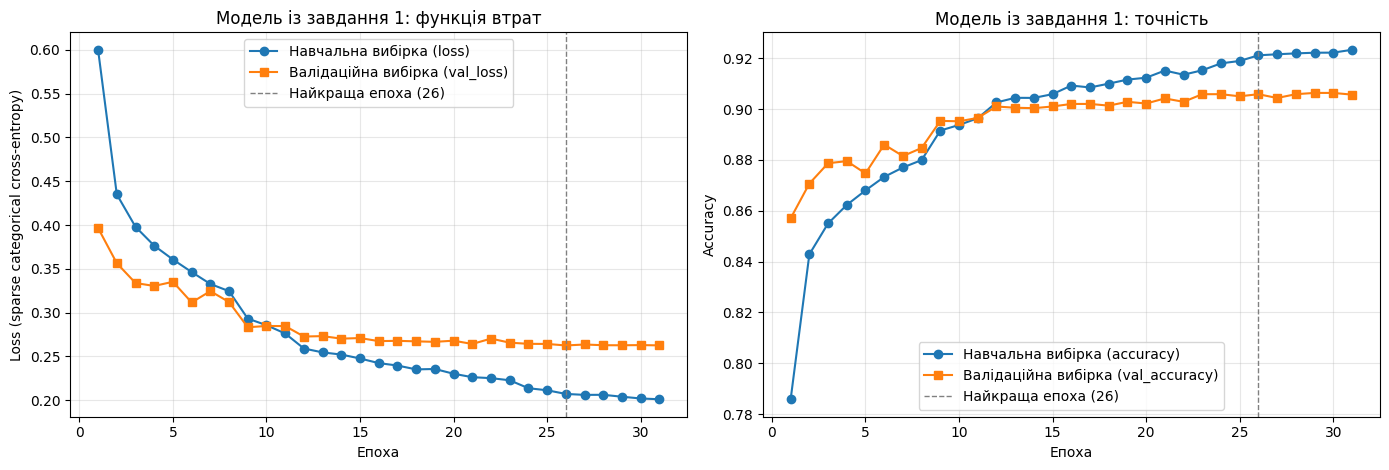

In [9]:
def plot_history(hist, title):
    """Графіки loss і accuracy для навчальної та валідаційної вибірок."""
    h = hist.history
    ep = np.arange(1, len(h['loss']) + 1)
    best = int(np.argmin(h['val_loss'])) + 1
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))

    ax[0].plot(ep, h['loss'], 'o-', label='Навчальна вибірка (loss)')
    ax[0].plot(ep, h['val_loss'], 's-', label='Валідаційна вибірка (val_loss)')
    ax[0].set_title(f'{title}: функція втрат')
    ax[0].set_ylabel('Loss (sparse categorical cross-entropy)')

    ax[1].plot(ep, h['accuracy'], 'o-', label='Навчальна вибірка (accuracy)')
    ax[1].plot(ep, h['val_accuracy'], 's-', label='Валідаційна вибірка (val_accuracy)')
    ax[1].set_title(f'{title}: точність')
    ax[1].set_ylabel('Accuracy')

    for a in ax:
        a.axvline(best, color='gray', ls='--', lw=1, label=f'Найкраща епоха ({best})')
        a.set_xlabel('Епоха')
        a.grid(alpha=0.3)
        a.legend()
    plt.tight_layout()
    plt.show()

plot_history(history, 'Модель із завдання 1')

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

Тестова loss:     0.3176
Тестова accuracy: 0.8959
Вимогу accuracy ≥ 0.87 ВИКОНАНО ✅

Класифікаційний звіт (модель із завдання 1):
              precision    recall  f1-score   support

 T-shirt/top     0.8453    0.8580    0.8516      1000
     Trouser     0.9898    0.9730    0.9813      1000
    Pullover     0.8095    0.8200    0.8147      1000
       Dress     0.8887    0.9100    0.8992      1000
        Coat     0.8193    0.8160    0.8176      1000
      Sandal     0.9837    0.9680    0.9758      1000
       Shirt     0.7296    0.7070    0.7181      1000
     Sneaker     0.9464    0.9710    0.9585      1000
         Bag     0.9789    0.9760    0.9775      1000
  Ankle boot     0.9668    0.9600    0.9634      1000

    accuracy                         0.8959     10000
   macro avg     0.8958    0.8959    0.8958     10000
weighted avg     0.8958    0.8959    0.8958     10000

Кількість помилок за справжнім класом (із 1000 зображень кожного класу):
  Shirt         293
  Coat          18

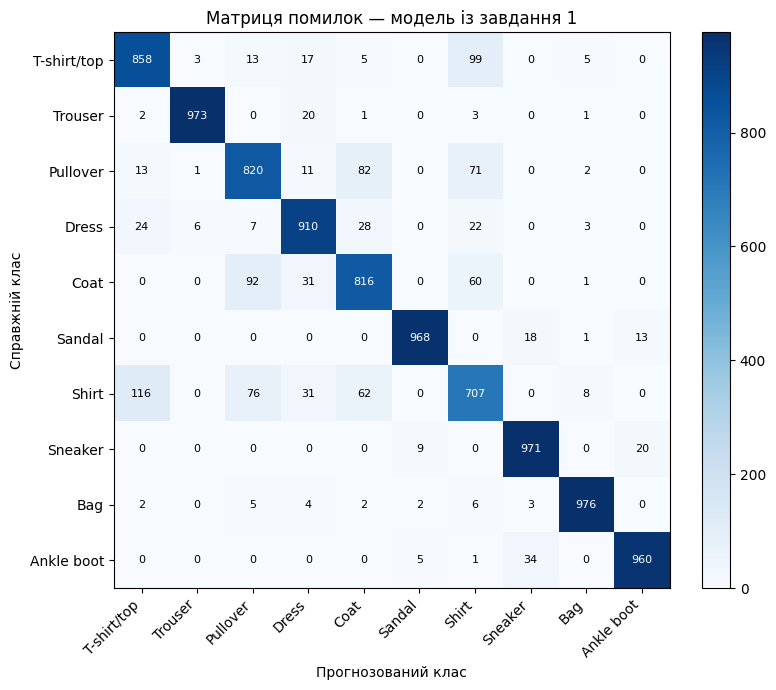

In [10]:
# Фінальна (одноразова) оцінка на тестовій вибірці
test_loss_1, test_acc_1 = model.evaluate(x_test, y_test, verbose=0)
print(f'Тестова loss:     {test_loss_1:.4f}')
print(f'Тестова accuracy: {test_acc_1:.4f}')
print('Вимогу accuracy ≥ 0.87', 'ВИКОНАНО ✅' if test_acc_1 >= 0.87 else 'НЕ виконано ❌')

y_prob_1 = model.predict(x_test, verbose=0)
y_pred_1 = np.argmax(y_prob_1, axis=1)

print('\nКласифікаційний звіт (модель із завдання 1):')
print(classification_report(y_test, y_pred_1, target_names=class_names, digits=4))


def error_analysis(cm, top=5):
    """Кількість помилок за класами та найчастіші переплутування."""
    errors = cm.sum(axis=1) - np.diag(cm)
    print('Кількість помилок за справжнім класом (із 1000 зображень кожного класу):')
    for c in np.argsort(-errors):
        print(f'  {class_names[c]:<12} {errors[c]:>4}')
    off = cm.copy()
    np.fill_diagonal(off, 0)
    print('\nНайчастіші переплутування (справжній клас → прогноз):')
    for flat in np.argsort(-off, axis=None)[:top]:
        t, p = np.unravel_index(flat, off.shape)
        print(f'  {class_names[t]} → {class_names[p]}: {off[t, p]}')


def plot_confusion(cm, title):
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(10))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticks(range(10))
    ax.set_yticklabels(class_names)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xlabel('Прогнозований клас')
    ax.set_ylabel('Справжній клас')
    ax.set_title(title)
    plt.colorbar(im, fraction=0.046)
    plt.tight_layout()
    plt.show()


cm_1 = confusion_matrix(y_test, y_pred_1)
error_analysis(cm_1)
plot_confusion(cm_1, 'Матриця помилок — модель із завдання 1')

### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

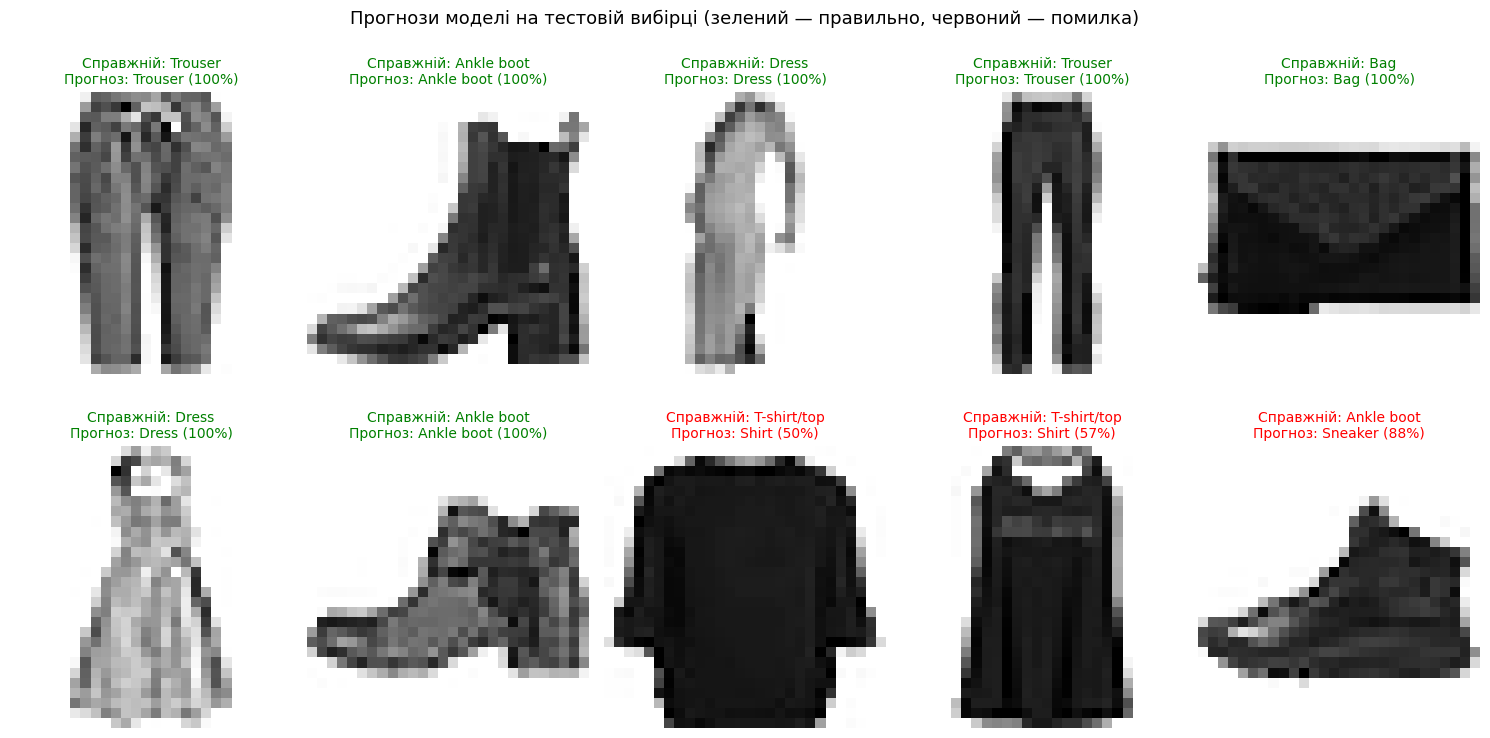

In [11]:
# 10 тестових зображень: 7 випадкових правильно класифікованих і 3 випадкові помилки,
# щоб було видно обидва варіанти підпису (зелений — правильно, червоний — помилка)
rng = np.random.default_rng(SEED)
right_idx = np.where(y_pred_1 == y_test)[0]
wrong_idx = np.where(y_pred_1 != y_test)[0]
show_idx = np.concatenate([rng.choice(right_idx, 7, replace=False),
                           rng.choice(wrong_idx, 3, replace=False)])

plt.figure(figsize=(15, 8))
for k, i in enumerate(show_idx):
    plt.subplot(2, 5, k + 1)
    plt.imshow(x_test[i], cmap='binary')
    ok = y_pred_1[i] == y_test[i]
    plt.title(f'Справжній: {class_names[y_test[i]]}\nПрогноз: {class_names[y_pred_1[i]]} '
              f'({y_prob_1[i].max():.0%})', color='green' if ok else 'red', fontsize=10)
    plt.axis('off')
plt.suptitle('Прогнози моделі на тестовій вибірці (зелений — правильно, червоний — помилка)', fontsize=13)
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Базова модель (Flatten → Dense 256 → Dropout 0,3 → Dense 128 → Dropout 0,3 → Dense 10, Adam з lr = 0,001) отримала на тестовій вибірці **accuracy = 0,8959** при **loss = 0,3176**. Вимогу щодо мінімальної точності **0,87 виконано** із запасом ≈2,6 в. п.

EarlyStopping зупинив навчання після 31 епохи і відновив ваги 26-ї епохи (val_accuracy = 0,906, val_loss = 0,263). ReduceLROnPlateau поступово зменшив швидкість навчання з 0,001 до ≈1,6·10⁻⁵. На графіках видно помірне перенавчання: після ~15-ї епохи навчальна loss продовжує спадати, а валідаційна виходить на плато (≈0,26–0,27). Dropout і рання зупинка не дали цьому розриву збільшитися.

Найбільше помилок модель робить на класах верхнього одягу зі схожим силуетом:
- **Shirt** — F1 = 0,72, 293 помилки з 1000; найчастіше її плутає з T-shirt/top (116 випадків);
- **Coat** — F1 = 0,82, 184 помилки; найчастіше прогнозується як Pullover (92);
- **Pullover** — F1 = 0,81, 180 помилок; найчастіше прогнозується як Coat (82);
- **T-shirt/top** — F1 = 0,85, 142 помилки; найчастіше прогнозується як Shirt (99).

На зображеннях 28×28 у відтінках сірого ці речі відрізняються лише дрібними деталями (комір, ґудзики, блискавка, довжина рукава). Повнозв’язна мережа після Flatten втрачає просторову структуру зображення, тому розрізняє такі деталі гірше. Найлегше розпізнаються Trouser (F1 = 0,98), Bag (0,98), Sandal (0,98), Ankle boot та Sneaker (≈0,96), бо їхня форма суттєво відрізняється від інших класів.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
# Установлення Keras Tuner (у Colab за замовчуванням не встановлений)
!pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

print('Keras Tuner:', kt.__version__)

Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# Ті самі нормалізовані дані (x_train / x_test у [0; 1]) і той самий стратифікований поділ
# train/validation, що й у завданні 1 (однаковий random_state => ідентичні вибірки).
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train, y_train, test_size=0.1, stratify=y_train, random_state=SEED)

print('Навчальна (для пошуку):              ', x_tr.shape, y_tr.shape)
print('Валідаційна (критерій val_accuracy): ', x_val.shape, y_val.shape)
print('Тестова (лише фінальне оцінювання):  ', x_test.shape, y_test.shape)
print(f'Діапазон значень: [{x_tr.min():.1f}; {x_tr.max():.1f}], dtype = {x_tr.dtype}')
print('Кількість прикладів кожного класу у валідаційній вибірці:', np.bincount(y_val))
# x_test, y_test у tuner.search() НЕ передаються.

Навчальна (для пошуку):               (54000, 28, 28) (54000,)
Валідаційна (критерій val_accuracy):  (6000, 28, 28) (6000,)
Тестова (лише фінальне оцінювання):   (10000, 28, 28) (10000,)
Діапазон значень: [0.0; 1.0], dtype = float32
Кількість прикладів кожного класу у валідаційній вибірці: [600 600 600 600 600 600 600 600 600 600]


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
L2_FACTOR = 1e-4      # коефіцієнт L2-регуляризації ваг прихованих шарів
TUNER_DROPOUT = 0.2   # Dropout після кожного прихованого шару


def build_model(hp):
    """Повертає скомпільовану модель для заданого набору гіперпараметрів hp."""
    model = keras.Sequential(name='tuned_mlp')
    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())

    # Кількість прихованих шарів: 1–3
    for i in range(hp.Int('num_layers', min_value=1, max_value=3)):
        model.add(Dense(
            units=hp.Int(f'units_{i}', min_value=32, max_value=512, step=32),  # 32–512, крок 32
            activation='relu',
            kernel_regularizer=l2(L2_FACTOR),
        ))
        model.add(Dropout(TUNER_DROPOUT))

    model.add(Dense(10, activation='softmax'))

    lr = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])  # 0.01, 0.001, 0.0001
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


# Перевірка: функція повертає скомпільовану модель (з типовими значеннями гіперпараметрів)
build_model(kt.HyperParameters()).summary()

Model: "tuned_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
MAX_TRIALS = 3  # як у вихідному прикладі; більше спроб => ширше покриття простору пошуку

tuner = RandomSearch(
    hypermodel=build_model,
    objective='val_accuracy',
    max_trials=MAX_TRIALS,
    executions_per_trial=1,
    seed=SEED,
    directory='keras_tuner_results',      # каталог збереження результатів пошуку
    project_name='fashion_mnist_lab10',
    overwrite=True,
)
tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
search_callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6),
]

# Пошук: лише навчальні та валідаційні дані (x_test не використовується)
tuner.search(x_tr, y_tr,
             validation_data=(x_val, y_val),
             epochs=20, batch_size=64,
             callbacks=search_callbacks, verbose=2)

tuner.results_summary()

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
best_layers = best_hp.get('num_layers')
best_units = [best_hp.get(f'units_{i}') for i in range(best_layers)]
best_lr = best_hp.get('learning_rate')
print('\nНайкращі гіперпараметри:')
print('  прихованих шарів:  ', best_layers)
print('  нейронів у шарах:  ', best_units)
print('  швидкість навчання:', best_lr)

# Перенавчаємо найкращу конфігурацію з нуля (до 50 епох) і зберігаємо історію навчання
keras.utils.set_random_seed(SEED)
best_model = tuner.hypermodel.build(best_hp)
best_model.summary()

history_tuned = best_model.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=50, batch_size=64,
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
               ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)],
    verbose=2,
)
epochs_2 = len(history_tuned.history['loss'])
best_epoch_2 = int(np.argmin(history_tuned.history['val_loss'])) + 1
print(f'\nНавчання зупинено після {epochs_2} епох; відновлено ваги найкращої епохи {best_epoch_2} '
      f'(val_accuracy = {history_tuned.history["val_accuracy"][best_epoch_2 - 1]:.4f}).')

best_model.save('fashion_mnist_tuned.keras')
print('Найкращу модель збережено: fashion_mnist_tuned.keras')

Trial 3 Complete [00h 00m 36s]
val_accuracy: 0.8684999942779541

Best val_accuracy So Far: 0.9049999713897705
Total elapsed time: 00h 03m 27s
Results summary
Results in keras_tuner_results/fashion_mnist_lab10
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 1 summary
Hyperparameters:
num_layers: 1
units_0: 480
learning_rate: 0.001
units_1: 288
Score: 0.9049999713897705

Trial 0 summary
Hyperparameters:
num_layers: 2
units_0: 32
learning_rate: 0.001
units_1: 32
Score: 0.8778333067893982

Trial 2 summary
Hyperparameters:
num_layers: 1
units_0: 256
learning_rate: 0.01
units_1: 512
Score: 0.8684999942779541

Найкращі гіперпараметри:
  прихованих шарів:   1
  нейронів у шарах:   [480]
  швидкість навчання: 0.001


Model: "tuned_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
844/844 - 6s - 7ms/step - accuracy: 0.8129 - loss: 0.5785 - val_accuracy: 0.8413 - val_loss: 0.4763 - learning_rate: 0.0010
Epoch 2/50
844/844 - 4s - 5ms/step - accuracy: 0.8534 - loss: 0.4545 - val_accuracy: 0.8537 - val_loss: 0.4461 - learning_rate: 0.0010
Epoch 3/50
844/844 - 5s - 5ms/step - accuracy: 0.8659 - loss: 0.4237 - val_accuracy: 0.8647 - val_loss: 0.4207 - learning_rate: 0.0010
Epoch 4/50
844/844 - 5s - 6ms/step - accuracy: 0.8724 - loss: 0.4065 - val_accuracy: 0.8820 - val_loss: 0.3911 - learning_rate: 0.0010
Epoch 5/50
844/844 - 4s - 5ms/step - accuracy: 0.8759 - loss: 0.3964 - val_accuracy: 0.8703 - val_loss: 0.4139 - learning_rate: 0.0010
Epoch 6/50

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
844/844 - 5s - 6ms/step - accuracy: 0.8790 - loss: 0.3874 - val_accuracy: 0.8818 - val_loss: 0.3954 - learning_rate: 0.0010
Epoch 7/50
844/844 - 4s - 5ms/step - accuracy: 0.8921 - loss: 0.3501 - val_accuracy: 0.8890 - val_loss: 0.3592 - 

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Тестова loss (з L2-штрафом): 0.3309
Тестова крос-ентропія:       0.2877   (модель із завдання 1: 0.3158)
Тестова accuracy:            0.8991   (модель із завдання 1: 0.8959)

Класифікаційний звіт (модель після Keras Tuner):
              precision    recall  f1-score   support

 T-shirt/top     0.8550    0.8550    0.8550      1000
     Trouser     0.9939    0.9770    0.9854      1000
    Pullover     0.8162    0.8260    0.8211      1000
       Dress     0.8964    0.9090    0.9027      1000
        Coat     0.8187    0.8310    0.8248      1000
      Sandal     0.9787    0.9660    0.9723      1000
       Shirt     0.7380    0.7240    0.7309      1000
     Sneaker     0.9482    0.9700    0.9590      1000
         Bag     0.9798    0.9710    0.9754      1000
  Ankle boot     0.9678    0.9620    0.9649      1000

    accuracy                         0.8991     10000
   macro avg     0.8993    0.8991    0.8991     10000
weighted avg     0.8993    0.8991    0.8991     10000



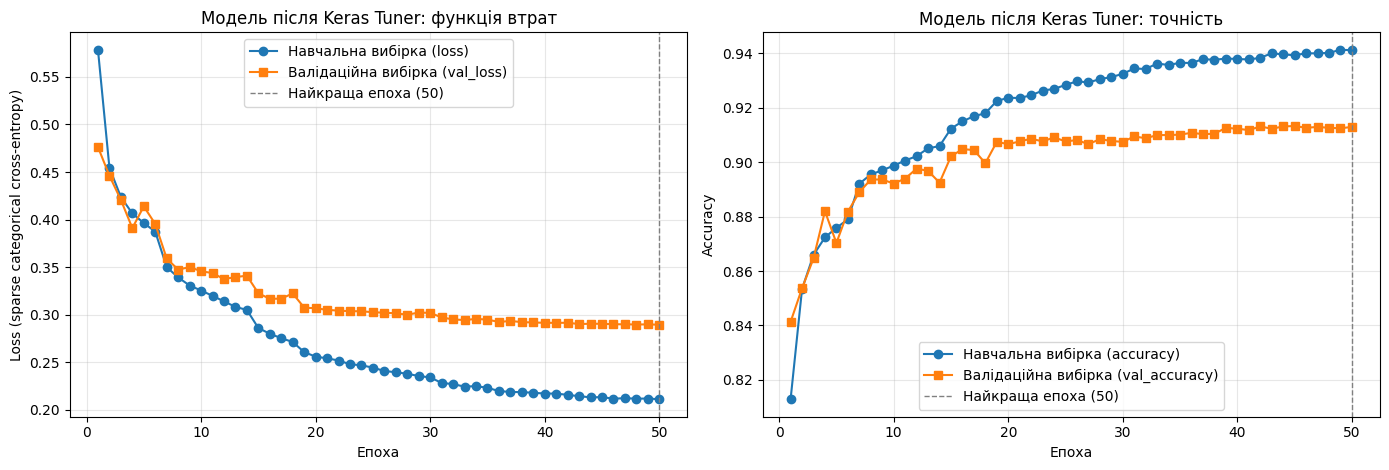

Кількість помилок за справжнім класом (із 1000 зображень кожного класу):
  Shirt         276
  Pullover      174
  Coat          169
  T-shirt/top   145
  Dress          91
  Ankle boot     38
  Sandal         34
  Sneaker        30
  Bag            29
  Trouser        23

Найчастіші переплутування (справжній клас → прогноз):
  Shirt → T-shirt/top: 106
  T-shirt/top → Shirt: 97
  Pullover → Coat: 81
  Coat → Pullover: 79
  Shirt → Pullover: 77


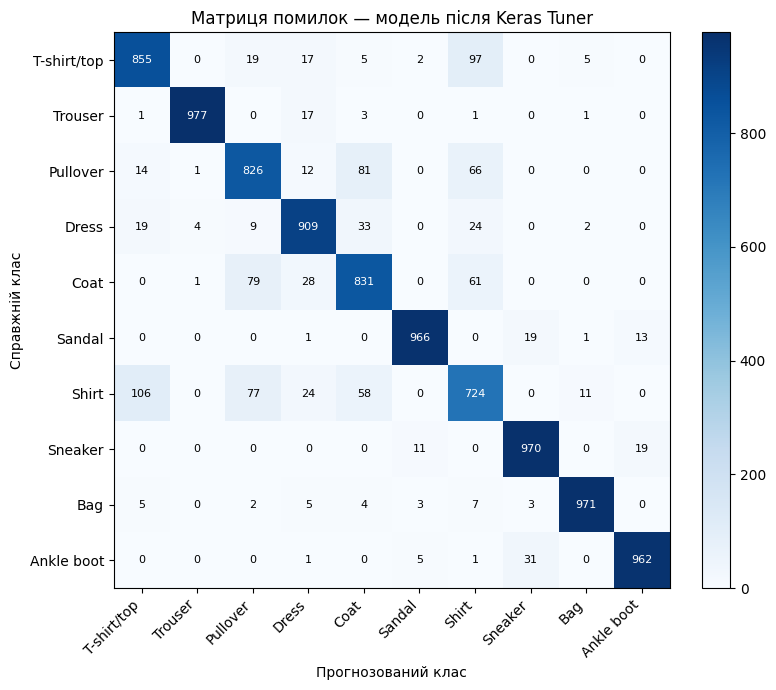

,Модель із завдання 1,Модель після Keras Tuner
Кількість прихованих шарів,2,1
Кількість нейронів,256 / 128,480
Швидкість навчання,0.001 (наприкінці 1.5625e-05),0.001 (наприкінці 7.8125e-06)
Точність на тестовій вибірці (accuracy),0.8959,0.8991
Втрати на тестовій вибірці (loss),0.3176 (крос-ентропія 0.3158),0.3309 (крос-ентропія 0.2877)
Кількість епох навчання,31 (найкраща 26),50 (найкраща 50)


In [17]:
# Фінальне оцінювання найкращої моделі на тестовій вибірці
test_loss_2, test_acc_2 = best_model.evaluate(x_test, y_test, verbose=0)
y_prob_2 = best_model.predict(x_test, verbose=0)
y_pred_2 = np.argmax(y_prob_2, axis=1)

# evaluate() для моделі з L2 повертає loss разом зі штрафом регуляризації,
# тому для коректного порівняння додатково рахуємо «чисту» крос-ентропію обох моделей.
ce_1 = log_loss(y_test, y_prob_1, labels=range(10))
ce_2 = log_loss(y_test, y_prob_2, labels=range(10))

print(f'Тестова loss (з L2-штрафом): {test_loss_2:.4f}')
print(f'Тестова крос-ентропія:       {ce_2:.4f}   (модель із завдання 1: {ce_1:.4f})')
print(f'Тестова accuracy:            {test_acc_2:.4f}   (модель із завдання 1: {test_acc_1:.4f})')

print('\nКласифікаційний звіт (модель після Keras Tuner):')
print(classification_report(y_test, y_pred_2, target_names=class_names, digits=4))

plot_history(history_tuned, 'Модель після Keras Tuner')

cm_2 = confusion_matrix(y_test, y_pred_2)
error_analysis(cm_2)
plot_confusion(cm_2, 'Матриця помилок — модель після Keras Tuner')


def lr_info(hist, lr0):
    lrs = hist.history.get('learning_rate') or hist.history.get('lr')
    return f'{lr0:g}' + (f' (наприкінці {float(lrs[-1]):g})' if lrs else '')


comparison = pd.DataFrame({
    'Модель із завдання 1': [
        len(HIDDEN_UNITS), ' / '.join(map(str, HIDDEN_UNITS)), lr_info(history, LEARNING_RATE),
        f'{test_acc_1:.4f}', f'{test_loss_1:.4f} (крос-ентропія {ce_1:.4f})', f'{epochs_1} (найкраща {best_epoch_1})'],
    'Модель після Keras Tuner': [
        best_layers, ' / '.join(map(str, best_units)), lr_info(history_tuned, best_lr),
        f'{test_acc_2:.4f}', f'{test_loss_2:.4f} (крос-ентропія {ce_2:.4f})', f'{epochs_2} (найкраща {best_epoch_2})'],
}, index=['Кількість прихованих шарів', 'Кількість нейронів', 'Швидкість навчання',
          'Точність на тестовій вибірці (accuracy)', 'Втрати на тестовій вибірці (loss)',
          'Кількість епох навчання'])
display(comparison)

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256 / 128 | 480 |
| Швидкість навчання | 0,001 (ReduceLROnPlateau знизив до ≈1,6·10⁻⁵) | 0,001 (ReduceLROnPlateau знизив до ≈7,8·10⁻⁶) |
| Точність на тестовій вибірці (accuracy) | **0,8959** | **0,8991** |
| Втрати на тестовій вибірці (loss) | 0,3176 (крос-ентропія 0,3158) | 0,3309 з L2-штрафом (крос-ентропія 0,2877) |
| Кількість епох навчання | 31 (EarlyStopping, найкраща — 26) | 50 (усі 50, найкраща — 50) |

*Примітка.* Для моделі з L2-регуляризацією model.evaluate() повертає крос-ентропію разом зі штрафом за величину ваг (≈0,043). Тому для коректного порівняння наведено ще й «чисту» крос-ентропію: за нею друга модель краща (0,288 проти 0,316).

Результати RandomSearch (3 спроби, критерій val_accuracy):

| Спроба | Прихованих шарів | Нейронів | Learning rate | val_accuracy |
|---|---|---|---|---|
| 0 | 2 | 32 / 32 | 0,001 | 0,8778 |
| **1** | **1** | **480** | **0,001** | **0,9050** |
| 2 | 1 | 256 | 0,01 | 0,8685 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
1. **Так, точність не нижче 0,87 у завданні 1 досягнуто.** Базова мережа 256→128 із Dropout 0,3 отримала на тестовій вибірці accuracy = 0,8959, що на ≈2,6 в. п. перевищує поріг.

2. **Оптимізація гіперпараметрів дала лише невелике покращення.** Тестова accuracy зросла з 0,8959 до 0,8991 (+0,32 в. п., це 32 правильні відповіді з 10 000), а тестова крос-ентропія знизилася з 0,316 до 0,288. Різниця невелика й близька до розкиду між запусками, тому не можна стверджувати, що налаштована модель суттєво краща. Причини:
   - RandomSearch мав лише 3 спроби, тобто перевірив мізерну частину простору пошуку (1–3 шари × 16 варіантів нейронів у кожному шарі × 3 значення learning rate);
   - базова модель уже була налаштована «вручну» на розумні значення.

   Налаштована модель навчалася всі 50 епох, і її val_loss ще повільно спадала, тож більша кількість епох або спроб могла б дати ще трохи кращий результат.

3. **Найкраща конфігурація — один прихований шар на 480 нейронів із learning rate = 0,001** (разом із Dropout 0,2 та L2 = 10⁻⁴).
   - Вузька мережа 2×32 виявилася надто малої місткості (val_accuracy 0,878).
   - Із learning rate = 0,01 навчання нестабільне: кроки Adam завеликі, і навіть ReduceLROnPlateau не врятував результат (0,869).
   - Отже, вирішальним є помірний learning rate (0,001) і достатня кількість нейронів.

   Результат може відрізнятися між запусками через:
   - випадкову ініціалізацію ваг;
   - перемішування даних у кожній епосі;
   - випадкові маски Dropout;
   - випадковий вибір конфігурацій у RandomSearch (за 3 спроби вибірка дуже мала);
   - паралельні обчислення на GPU/CPU, які можуть бути недетермінованими.

   EarlyStopping і ReduceLROnPlateau реагують на шум val_loss, тому кількість епох теж змінюється. У ноутбуці зафіксовано SEED = 42 і ввімкнено детерміновані операції TensorFlow, тож результати відтворюються в тому самому середовищі. Інший seed, апаратне забезпечення або версія бібліотек дадуть дещо інші числа (зазвичай у межах кількох десятих відсотка).

4. **Найскладніше класифікувати клас Shirt (сорочка)**: F1 ≈ 0,72–0,73, 276–293 помилки з 1000 в обох моделях. Далі йдуть **Pullover, Coat** (F1 ≈ 0,81–0,83) і **T-shirt/top** (F1 ≈ 0,85). Основні переплутування:
   - Shirt ↔ T-shirt/top — ≈100 випадків у кожному напрямку;
   - Coat ↔ Pullover — ≈80 випадків;
   - Shirt → Pullover — ≈77 випадків.

   Усе це верхній одяг зі схожим силуетом, який на зображенні 28×28 відрізняється лише дрібними деталями. Найлегше розпізнаються Trouser, Bag, Sandal, Sneaker та Ankle boot (F1 ≥ 0,96). Добір гіперпараметрів не змінив структуру помилок. Щоб краще розрізняти схожі класи, варто перейти від повнозв’язної мережі до згорткової (CNN): вона враховує локальні просторові ознаки (комір, ґудзики, блискавку) і на Fashion MNIST зазвичай дає помітно вищу точність.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.